# 📐 Cuaderno 01 — Interpolación

**Métodos Numéricos · Unidad 4: Ajuste de curvas e interpolación**

Tema 4.1. Cada método sigue el mismo camino: **explicación → a mano → programar → laboratorio**.

In [1]:
#@title ⚙️ Entorno — ejecuta esta celda PRIMERO
# ---------------------------------------------------------------
# En tu computadora usa los archivos locales, sin repositorio.
# En Google Colab pide UNA vez el enlace de tu fork, lo guarda en tu
# Drive y a partir de ahí lo reutiliza solo.
# ---------------------------------------------------------------
import json
import os
import subprocess
import sys

CUADERNO = 'u4_01_interpolacion'
TAREA_ID = 'U4_01_Interpolacion'
REPO_NOMBRE = "U4_Repo"
GUARDADO = os.path.join("CursoMN", "u4_repo.json")   # relativo a MyDrive

try:
    import google.colab  # noqa: F401
    ES_COLAB = True
except ImportError:
    ES_COLAB = False


def _raiz_local():
    """Sube desde la carpeta actual hasta encontrar lib/robomat.py."""
    candidatos = [os.getcwd()]
    nb = globals().get("__vsc_ipynb_file__")
    if nb:
        candidatos.append(os.path.dirname(os.path.abspath(nb)))
    for base in candidatos:
        b = base
        for _ in range(6):
            if os.path.exists(os.path.join(b, "lib", "robomat.py")):
                return b
            padre = os.path.dirname(b)
            if padre == b:
                break
            b = padre
    return None


def _normaliza(enlace):
    enlace = (enlace or "").strip().rstrip("/")
    if enlace.endswith(".git"):
        enlace = enlace[:-4]
    if not enlace.startswith("https://github.com/"):
        raise ValueError("Necesito un enlace https://github.com/USUARIO/"
                         + REPO_NOMBRE + " (tu fork).")
    return enlace


if not ES_COLAB:
    REPO = _raiz_local()
    if REPO is None:
        raise RuntimeError(
            "No encontré la raíz del repositorio (lib/robomat.py).\n"
            "Abre el cuaderno dentro de U4_Repo o ejecútalo desde esa carpeta.")
    print("Modo        : local (sin repositorio)")
    print("Repositorio :", REPO)
else:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = "/content/drive/MyDrive"
    ruta_json = os.path.join(DRIVE, GUARDADO)

    guardado = {}
    if os.path.exists(ruta_json):
        try:
            with open(ruta_json, encoding="utf-8") as f:
                guardado = json.load(f)
        except Exception:
            guardado = {}

    enlace = (guardado.get("repo") or "").strip()
    if enlace:
        print("✅ Repositorio guardado:", enlace)
        print("   (si cambió, edita la caja de abajo y pulsa el botón)")
    else:
        try:
            enlace = input("Pega el enlace de TU fork de U4_Repo: ")
        except Exception:
            enlace = ""
        enlace = (enlace or "").strip()
        if not enlace:
            raise RuntimeError(
                "Sin repositorio no puedo continuar en Colab.\n"
                "Haz fork del repositorio del curso y pega su enlace.")

    enlace = _normaliza(enlace)
    REPO = os.path.join(DRIVE, "CursoMN", REPO_NOMBRE)

    if not os.path.exists(REPO):
        print("Clonando tu repositorio…")
        subprocess.run(["git", "clone", enlace + ".git", REPO], check=True)
    else:
        print("Actualizando tu repositorio…")
        subprocess.run(["git", "-C", REPO, "pull", "--ff-only"], check=False)

    with open(ruta_json, "w", encoding="utf-8") as f:
        json.dump({"repo": enlace}, f, indent=1)
    print("Repositorio :", REPO)

# --- Motor de calificación -------------------------------------------
# Se usa el código fuente si está (rama `test`, para depurar); si no, el blob
# empaquetado de grader/, que es lo que recibe el alumno.
_ruta_modulos = os.path.join(REPO, "lib", "mn_motor")
_ruta_blob = os.path.join(REPO, "grader", CUADERNO + ".txt")

_lib = os.path.join(REPO, "lib")
if _lib not in sys.path:
    sys.path.insert(0, _lib)          # ajuste_curvas y, si está, mn_motor

if os.path.isdir(_ruta_modulos):
    import mn_motor as _motor
    globals().update({n: getattr(_motor, n) for n in _motor.__all__})
    print("Motor       : módulos de lib/mn_motor (modo profesor)")
else:
    import base64
    import zlib

    if not os.path.exists(_ruta_blob):
        raise FileNotFoundError(
            "No encuentro el motor: falta grader/" + CUADERNO + ".txt\n"
            "Clona el repositorio completo (incluye la carpeta grader/).")
    with open(_ruta_blob, encoding="utf-8") as f:
        codigo = zlib.decompress(base64.b64decode(f.read().strip())).decode("utf-8")
    _MOTOR = {"__name__": "mn_motor_blob", "__file__": "<blob>"}
    exec(compile(codigo, "<blob>", "exec"), _MOTOR)
    globals().update({n: _MOTOR[n] for n in _MOTOR["__all__"]})
    print("Motor       : blob verificado de grader/")

usar_cuaderno(CUADERNO, TAREA_ID)

# --- Preludio estilo MATLAB y herramientas de gráficas ---------------
with open(os.path.join(REPO, "lib", "robomat.py"), encoding="utf-8") as f:
    exec(f.read(), globals())

if REPO not in sys.path:
    sys.path.insert(0, REPO)          # para importar ejercicios/
sys.path.append(os.path.join(REPO, "tools"))
import importlib
import visualizar
importlib.reload(visualizar)

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["figure.dpi"] = 110
print("Preludio    : lib/robomat.py · tools/visualizar.py")
print("\nListo. Ejecuta la celda de identificación.")

Modo        : local (sin repositorio)
Repositorio : o:\Mi unidad\CursoMN\U4 Ajuste de curvas e interpolación\U4_Repo
Motor       : módulos de lib/mn_motor (modo profesor)
Preludio    : lib/robomat.py · tools/visualizar.py

Listo. Ejecuta la celda de identificación.


In [2]:
#@title 👤 Identificación (número de control)
# ---------------------------------------------------------------
# En Colab se toma tu correo institucional; en local se escribe uno
# de prueba. De ahí sale el número de control que siembra tus datos.
# ---------------------------------------------------------------
if ES_COLAB:
    import requests

    from google.colab import auth
    import google.auth
    import google.auth.transport.requests

    auth.authenticate_user()
    creds, _ = google.auth.default()
    creds.refresh(google.auth.transport.requests.Request())
    info = requests.get(
        "https://www.googleapis.com/drive/v3/about?fields=user",
        headers={{"Authorization": "Bearer " + creds.token}}, timeout=20).json()
    cuenta = info.get("user", {{}})
    email = cuenta.get("emailAddress", "")
    nombre = cuenta.get("displayName", "")
else:
    email = "m16330887@hermosillo.tecnm.mx"   # <-- cambia por el tuyo
    nombre = ""

if not (email and "@" in email and email.lower().endswith(".tecnm.mx")):
    from IPython.display import HTML, display
    display(HTML(
        '<p style="color:#b00020;background:#ffe0e0;padding:12px;'
        'border-radius:8px;font-weight:bold">⛔ Usa tu correo @….tecnm.mx</p>'))
    raise RuntimeError("Necesito tu correo institucional para sembrar tus datos.")

print("Alumno :", email)
print("NC     :", extraer_nc(email))
MI_TAREA = generar_tarea(email, nombre)
print("Cuaderno:", MI_TAREA["cuaderno"],
      "·", len(MI_TAREA["preguntas"]), "preguntas")

Alumno : m16330887@hermosillo.tecnm.mx
NC     : 16330887
Cuaderno: u4_01_interpolacion · 4 preguntas


---

## Antes de interpolar: polinomios de Taylor

Una función suave puede aproximarse cerca de un punto $a$ mediante una suma infinita de potencias construida con sus derivadas en ese punto. La **serie de Taylor** es

$$f(x)=\sum_{k=0}^{\infty}\frac{f^{(k)}(a)}{k!}(x-a)^k,$$

cuando la serie converge a $f(x)$ en infinitas iteraciones. 

En la práctica se conservan solo los primeros $n+1$ términos: el **polinomio de Taylor** de grado $n$,

$$T_n(x)=\sum_{k=0}^{n}\frac{f^{(k)}(a)}{k!}(x-a)^k.$$

Por ejemplo, para $e^x$ alrededor de $a=0$, $T_2(x)=1+x+\frac{x^2}{2}$. En $x=0.2$ da $1.22$, mientras que $e^{0.2}\approx1.2214$; la diferencia es el error de truncamiento algorítmico. Bajo las condiciones del teorema de Taylor, ese error puede escribirse como

$$R_n(x)=f(x)-T_n(x)=\frac{f^{(n+1)}(\xi)}{(n+1)!}(x-a)^{n+1},$$

para algún punto $\xi$ entre $a$ y $x$.

**Conexión con esta unidad:** Taylor usa derivadas en un punto para aproximar localmente; la **interpolación** usa valores conocidos en varios nodos y construye un polinomio que pasa por ellos. Aquí trabajaremos con esta segunda idea.

---

## Método 1 · Interpolación lineal

Es unir dos puntos con una recta. Por triángulos semejantes,

$$f_1(x)=f(x_0)+\frac{f(x_1)-f(x_0)}{x_1-x_0}(x-x_0) \tag{18.2}$$

El cociente es la pendiente y, además, una aproximación a la primera derivada.
Cuando más cerca estén los nodos, mejor representa la recta a la curva.

![Figura 18.2 del libro: interpolación lineal](https://raw.githubusercontent.com/ITH-MGL-MN/U4_Repo/refs/heads/main/docs/figuras/libro/fig18-2_interpolacion_lineal.jpg)

In [3]:
#@title ✏️ Actividad a mano · Interpolación lineal
EJ_1 = mano_enunciado("INTERP_LINEAL")

#### ✏️ Interpolación lineal — actividad a mano

Se conocen dos valores: $f(2) = 1$ y $f(4) = 8$.

Estima $f(3)$ por interpolación lineal, ecuación (18.2).

>>> Reporta **$f(x)$** con 4 decimales.

**🔢 Resolución paso a paso.**

1. Identifica el intervalo $[x_0,x_1]$ que contiene a $x$.
2. Anota $y_0 = f(x_0)$ y $y_1 = f(x_1)$
3. Calcula la pendiente $m=\dfrac{y_1-y_0}{x_1-x_0}$
4. Evalúa $y=y_0+m(x-x_0)$.

In [4]:
#@title ✅ Comprueba tus valores a mano · Interpolación lineal
# Reporta los números que obtuviste, con 4 decimales.
x0 = 2
x1 = 4
x = 3
y0 = 1
y1 = 8
m = (y1 - y0) / (x1 - x0)
y = y0 + m * (x - x0)
#fx = 0.0
mano_comprueba("INTERP_LINEAL", y)

| valor | reportado | ¿coincide? |
|---|---:|:---:|
| $f(x)$ | 4.5 | ✅ |

✅ **Actividad a mano correcta.**

True

### 💻 Programa la función

Abre `ejercicios/interpolacion/interpolacion_lineal.py` (en Codespaces) o copia la plantilla aquí abajo.
El método completo debe **llamar** a sus piezas: no repitas la cuenta.

In [5]:
#@title ▶️ Prueba tu función con el ejemplo genérico
from ejercicios.interpolacion.interpolacion_lineal import *
practica("f_interp_lineal")

Probando `interpolacion_lineal` con el ejemplo del enunciado…
✅ Coincide con la referencia.
1.0


True

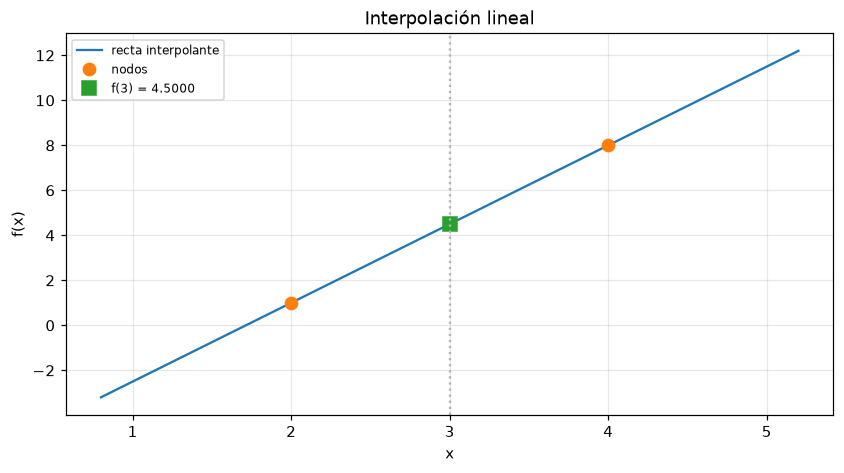

In [6]:
#@title 📊 Laboratorio · Interpolación lineal
visualizar.laboratorio("INTERP_LINEAL", EJ_1)

In [ ]:
#@title 🧪 Pregunta 1 · Interpolación Lineal
# Cuando tu función ya funcione, contéstala aquí.
pregunta(1)

---

## Método 2 · Coeficientes de la parábola

Con tres puntos se ajusta el único polinomio de segundo grado en la forma de Newton:

$$f_2(x) = b_0 + b_1(x-x_0) + b_2(x-x_0)(x-x_1) \tag{18.3}$$

Si definimos las dos pendientes entre tramos consecutivos como:

$$m_1 = \frac{y_1 - y_0}{x_1 - x_0} \qquad \text{y} \qquad m_2 = \frac{y_2 - y_1}{x_2 - x_1}$$

los coeficientes se simplifican a:

$$b_0 = y_0 \tag{18.4}$$

$$b_1 = m_1 \tag{18.5}$$

$$b_2 = \frac{m_2 - m_1}{x_2 - x_0} \tag{18.6}$$

Los dos primeros términos ($b_0$ y $b_1$) forman la recta; $b_2$ mide cómo cambia la pendiente para dar la curvatura.

In [7]:
#@title ✏️ Actividad a mano · Coeficientes de la parábola
EJ_2 = mano_enunciado("COEF_CUADRATICOS")

#### ✏️ Coeficientes de la parábola — actividad a mano

Ajusta la parábola que pasa por

| $x$ | 1 | 2 | 4 |
|---|---|---|---|
| $f(x)$ | 0 | 3 | 21 |

Calcula $b_1$ con (18.5) y $b_2$ con (18.6).

>>> Reporta **$b_1$,\ $b_2$** con 4 decimales.

In [8]:
#@title ✅ Comprueba tus valores a mano · Coeficientes de la parábola
# Reporta los números que obtuviste, con decimales.
x0 = 1
x1 = 2
x2 = 4
y0 = 0
y1 = 3
y2 = 21

m1 = (y1 - y0) / (x1 - x0)
m2 = (y2 - y1) / (x2 - x1)

b0 = y0
b1 = m1
b2 = (m2 - m1) / (x2 - x0)

mano_comprueba("COEF_CUADRATICOS", [b1, b2])

| valor | reportado | ¿coincide? |
|---|---:|:---:|
| $b_1$ | 3 | ✅ |
| $b_2$ | 2 | ✅ |

✅ **Actividad a mano correcta.**

True

### 💻 Programa la función

Abre `ejercicios/interpolacion/coeficientes_cuadraticos.py` (en Codespaces) o copia la plantilla aquí abajo.
El método completo debe **llamar** a sus piezas: no repitas la cuenta.

In [9]:
#@title 💻 Tu función · Coeficientes de la parábola
from ejercicios.interpolacion.coeficientes_cuadraticos import *
practica("f_coef_cuadraticos")

Probando `coeficientes_cuadraticos` con el ejemplo del enunciado…
✅ Coincide con la referencia.


<IPython.core.display.Math object>

True

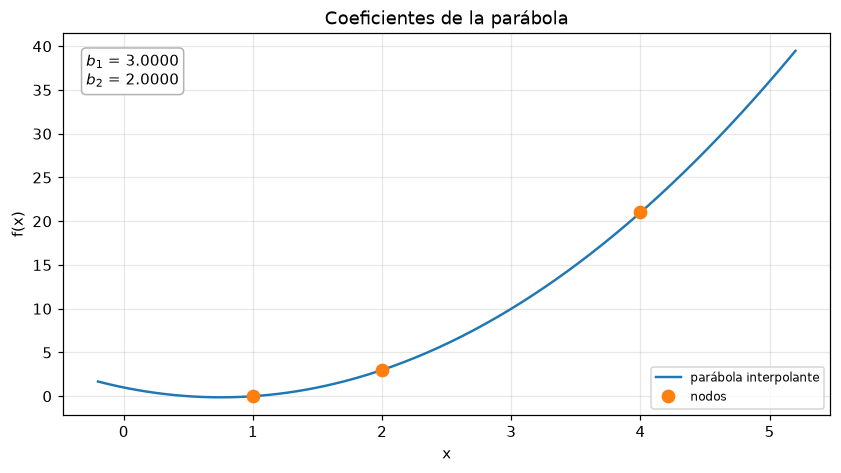

In [10]:
#@title 📊 Laboratorio · Coeficientes de la parábola
visualizar.laboratorio("COEF_CUADRATICOS", EJ_2)

In [11]:
#@title 🧪 Pregunta 2 · Coeficientes de la parábola
# Cuando tu función ya funcione, contéstala aquí.
pregunta(2)

### Pregunta 2 — Coeficientes de la parábola

Programa `coeficientes_cuadraticos` con el algoritmo de **Coeficientes de la parábola**. El método debe llamar a sus pasos sueltos.

> 💻 **Esta respuesta no se teclea:** es la función `coeficientes_cuadraticos` que definiste arriba.
>
> Firma: `coeficientes_cuadraticos(...)`
>
> Compruébala antes de enviar con `practica('f_coef_cuadraticos')`.

---

## Método 3 · Interpolación cuadrática

Ya con $b_0, b_1, b_2$ se evalúa (18.3) en el punto pedido. Esta
función **debe llamar** a `coeficientes_cuadraticos`: la pieza y el método no
se programan dos veces.

In [12]:
#@title ✏️ Actividad a mano · Interpolación cuadrática
EJ_3 = mano_enunciado("INTERP_CUADRATICA")

#### ✏️ Interpolación cuadrática — actividad a mano

Ajusta la parábola que pasa por

| $x$ | 1 | 2 | 4 |
|---|---|---|---|
| $f(x)$ | 6 | 10 | 24 |

Calcula $b_1$ con (18.5) y $b_2$ con (18.6).

Estima $f(2.5)$ con (18.3).

>>> Reporta **$f(x)$** con 4 decimales.

In [13]:
#@title ✅ Comprueba tus valores a mano · Interpolación cuadrática
# Reporta los números que obtuviste, con 4 decimales.
mano_comprueba("INTERP_CUADRATICA", [0.0])

| valor | reportado | ¿coincide? |
|---|---:|:---:|
| $f(x)$ | 0 | ❌ |

❌ Todavía hay valores fuera de tolerancia. Revisa el paso y no redondees a la mitad del cálculo.

False

### 💻 Programa la función

Abre `ejercicios/interpolacion/interpolacion_cuadratica.py` (en Codespaces) o copia la plantilla aquí abajo.
El método completo debe **llamar** a sus piezas: no repitas la cuenta.

In [ ]:
#@title 💻 Tu función · Interpolación cuadrática
from ejercicios.interpolacion.interpolacion_cuadratica import *

In [ ]:
#@title ▶️ Prueba tu función con el ejemplo genérico
practica("f_interp_cuadratica")

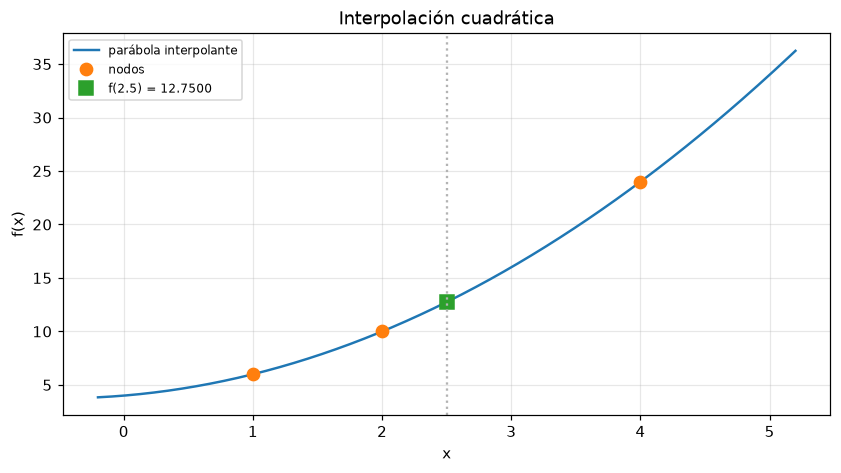

In [14]:
#@title 📊 Laboratorio · Interpolación cuadrática
visualizar.laboratorio("INTERP_CUADRATICA", EJ_3)

In [ ]:
#@title 🧪 Pregunta 3 · Interpolación cuadrática
# Cuando tu función ya funcione, contéstala aquí.
pregunta(3)

---

## Método 4 · Error con un punto extra

Si se tiene un nodo más de lo necesario, se estima el error:

$$R_n\cong f[x_{n+1},x_n,\dots,x_0]\prod_{i=0}^{n}(x-x_i) \tag{18.18}$$

Es la diferencia entre la predicción de grado $n+1$ y la de grado $n$.

In [ ]:
#@title ✏️ Actividad a mano · Error con un punto extra
EJ_4 = mano_enunciado("ERROR_INTERP")

In [ ]:
#@title ✅ Comprueba tus valores a mano · Error con un punto extra
# Reporta los números que obtuviste, con 4 decimales.
mano_comprueba("ERROR_INTERP", [0.0])

### 💻 Programa la función

Abre `ejercicios/interpolacion/error_estimado_interpolacion.py` (en Codespaces) o copia la plantilla aquí abajo.
El método completo debe **llamar** a sus piezas.

In [ ]:
#@title 💻 Tu función · Error con un punto extra
from ejercicios.interpolacion.error_estimado_interpolacion import *

In [ ]:
#@title ▶️ Prueba tu función con el ejemplo genérico
practica("f_error_interp")

In [ ]:
#@title 📊 Laboratorio · Error con un punto extra
visualizar.laboratorio("ERROR_INTERP", EJ_4)

In [ ]:
#@title 🧪 Pregunta 4 · Error con un punto extra
# Cuando tu función ya funcione, contéstala aquí.
pregunta(4)

In [ ]:
#@title ✅ 1 · Verificación de los ejercicios a mano
mano_comprueba_todos(["INTERP_LINEAL", "COEF_CUADRATICOS", "INTERP_CUADRATICA", "ERROR_INTERP"])

In [ ]:
#@title 📝 2 · Verificación de todas las preguntas (no envía nada)
puntos, maximo = calificar()

In [ ]:
#@title 📤 3 · Envío de las respuestas
enviar(email)

In [ ]:
#@title 🔎 4 · Verificación de lo que ya está enviado (no envía nada)
consultar_calificacion()